Import Libraries and Load Dataset for Training

In [20]:
import pandas as pd
import numpy as np
import joblib

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Set option to display all the columns
pd.set_option('display.max_columns', None)

In [10]:
# Load Training dataset
train_dataset = pd.read_csv("data/train.csv")

print("Dataset Dimensions:", train_dataset.shape)
train_dataset.head()

train_dataset.info()

# Check for missing Values
train_dataset.isnull().sum()



Dataset Dimensions: (2000, 21)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   i

battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64


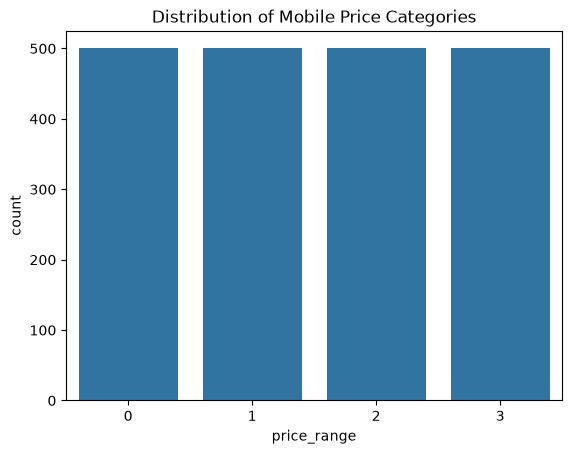

Features Shape: (2000, 20)
Target Shape: (2000,)


In [11]:
# Set Features and Target
X = train_dataset.drop("price_range", axis=1)
y = train_dataset["price_range"]

print(y.value_counts())

# Plot Class Distribution
sns.countplot(x=y)
plt.title("Distribution of Mobile Price Categories")
plt.show()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

In [12]:
# Split data for Train-Test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=18,
    stratify=y
)

In [21]:
# Scale the data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the Scaled data
joblib.dump(scaler, "model/scaler.pkl")

# Logistic Regression
logRegression = LogisticRegression(max_iter=5000, random_state=18)

logRegression.fit(X_train_scaled, y_train)

lr_pred = logRegression.predict(X_test_scaled)
lr_prob = logRegression.predict_proba(X_test_scaled)


# Save Logistic Regression Model
joblib.dump(logRegression, "model/logistic_regression.pkl")

['model/logistic_regression.pkl']